# Violin plots for all finished feature combinations

Discovers every combination that `run_feature_combinations.py` has already finished
(i.e. its `.../final/metrics_proposal_100_configs_<CONFIG>_<features>_stable_window.csv` exists),
loads them together with the benchmark detectors (ADWIN, KSWIN, PH, CUSUM, EWMA) and draws the
same metric/delay violin figure as in `KALEIDO_post_processing_stable_windows.ipynb`.

Re-run the notebook whenever more combinations have finished — nothing is hardcoded.

# Imports

In [2]:
from pathlib import Path as _Path
import os as _os

for _candidate in (_Path.cwd(), *_Path.cwd().parents):
    if (_candidate / "KALEIDO_multi_instance.py").is_file() and (_candidate / "stable_windows.csv").is_file():
        _code_dir = _candidate
        break
    _nested = _candidate / "results_all_in_one_code"
    if (_nested / "KALEIDO_multi_instance.py").is_file() and (_nested / "stable_windows.csv").is_file():
        _code_dir = _nested
        break
else:
    raise FileNotFoundError("Could not locate results_all_in_one_code; start this notebook inside the repository")

_os.chdir(_code_dir)
(_code_dir / "figures").mkdir(exist_ok=True)
(_code_dir / "example_runs").mkdir(exist_ok=True)
import re
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import numpy as np
import pandas as pd
import seaborn as sns

mpl.rcParams["pdf.fonttype"] = 42   # TrueType, not Type 3
mpl.rcParams["ps.fonttype"] = 42


# Configuration

In [1]:
CONFIG = "config_all_trans_1_data_only"


In [3]:

# The run loop is started from the project root, so results live in
# <project_root>/results_all_in_one_code/<CONFIG>/<features>/final/...
# The notebooks live one level below the project root (they read "../metrics_...csv"),
# hence the ".." default. Adjust if you run this from somewhere else.
PROJECT_ROOT = Path("..")
if not (PROJECT_ROOT / "results_all_in_one_code").exists() and Path("results_all_in_one_code").exists():
    PROJECT_ROOT = Path(".")

RESULTS_ROOT = PROJECT_ROOT / "results_all_in_one_code" / CONFIG
BENCHMARK_DIR = PROJECT_ROOT / "results_all_in_one_code" / "benchmark_results" / "metrics"
BENCHMARKS = ["ADWIN", "KSWIN", "PH", "CUSUM", "EWMA"]

EXCLUDE_TS = ["friedman_no_drifts"]   # same as in the original notebook

# Short labels for the x-axis, so "second_gradient+third_derivative+season" stays readable
FEATURE_ABBREV = {
    "normal_data": "raw",
    "gradient": "gr",
    "second_gradient": "2d",
    "third_derivative": "3d",
    "fourth_derivative": "4d",
    "fifth_derivative": "5d",
    "tenth_derivative": "10d",
    "trend": "tr",
    "season": "se",
    "fft_transform": "fft",
    "ttest_ind": "tt",
}

# ---- what every "top-N" figure shows -------------------------------------------------
TOP_N = 10                 # best-N combinations by F1 ...
OURS = "se+gr"             # ... plus this one, always included and shaded blue
                           # ("se+gr" = results_all_in_one_code/<CONFIG>/season+gradient, the run used
                           #  in KALEIDO_post_processing_stable_windows.ipynb; note that the
                           #  separate "gradient+season" run shows up as "gr+se")

# ---- display names (data keeps the raw names; these are only used for drawing) -------
METRIC_TITLES = {
    "F1 Score":                               "F1",
    "Miss Detection Rate":                    "Miss detection rate",
    "Sum Both Early and Late Detections":     r"Localization error $\Delta$",
    "Sum Both Early and Late Detections end": r"Alarm latency $L$",
}
TS_TITLES = {
    "AR4_linear_1":              "AR4 linear",
    "AR4_nonlinear_1":           "AR4 nonlinear",
    "friedman_2_drifts":         "Friedman 2 drifts",
    "friedman_5_drifts":         "Friedman 5 drifts",
    "infocom_4G_add_hour":       "Operational 4G",
    "infocom_4G_add_hour_trend": "Operational 4G trend",
    "infocom_5G_add_hour":       "Operational 5G",
    "infocom_5G_add_hour_trend": "Operational 5G trend",
    "random_easy":               "Random easy",
    "random_noisy":              "Random noisy",
    "rolling_mean":              "Rolling mean",
}
MODEL_TITLES = {
    OURS: "season+gr",
}

MODEL_COLORS = {
    "raw": "red",            # or "#d62728" for a less saturated red
    # OURS: "steelblue",     # uncomment if you want season+gr coloured too
}

# keyword arguments shared by every plot call below
PLOT_KW = dict(
    highlight=[OURS],
    metric_titles=METRIC_TITLES,
    ts_titles=TS_TITLES,
    model_titles=MODEL_TITLES,
    model_colors=MODEL_COLORS,
    fontsize=16,
)

print("RESULTS_ROOT  :", RESULTS_ROOT.resolve())
print("BENCHMARK_DIR :", BENCHMARK_DIR.resolve())


RESULTS_ROOT  : 
BENCHMARK_DIR : 


# Helper functions

In [4]:
def std_upper(x):
    m = x.mean()
    above_mean = x[x >= m]
    N = len(above_mean)
    if N <= 0:
        return np.nan
    return ((abs(above_mean - m) ** 2).sum() / N) ** 0.5


def std_lower(x):
    m = x.mean()
    below_mean = x[x < m]
    N = len(below_mean)
    if N <= 0:
        return np.nan
    return ((abs(below_mean - m) ** 2).sum() / N) ** 0.5


group_cols = ["id", "time_series", "config"]
metric_cols = [
    "True Positives", "False Positives", "Precision", "Recall", "F1 Score",
    "Miss Detection Rate",
    "Sum Late Detections", "Sum Early Detections",
    "Sum Both Early and Late Detections",
    "Sum Late Detections end", "Sum Early Detections end", "Sum Both Early and Late Detections end",
]


def aggregate_per_ts(df, by=("time_series",)):
    """Mean / std / one-sided std of every metric per time series (same as the original notebook)."""
    return (
        df.groupby(list(by))
        .agg(
            n_samples=("id", "count"),
            **{f"{c}_mean": (c, "mean") for c in metric_cols},
            **{f"{c}_std": (c, "std") for c in metric_cols},
            **{f"{c}_std_up": (c, std_upper) for c in metric_cols},
            **{f"{c}_std_low": (c, std_lower) for c in metric_cols},
        )
        .reset_index()
    )


def short_label(features: str) -> str:
    return "+".join(FEATURE_ABBREV.get(f, f) for f in features.split("+"))

# Discover finished feature combinations

In [5]:
MARKER_RE = re.compile(
    rf"^metrics_proposal_100_configs_{re.escape(CONFIG)}_(?P<features>.+)_stable_window\.csv$"
)

finished = {}
for csv_path in sorted(RESULTS_ROOT.glob("*/final/metrics_proposal_100_configs_*_stable_window.csv")):
    m = MARKER_RE.match(csv_path.name)
    if not m:
        continue
    features = m.group("features")
    # sanity: the folder name should match the feature string
    if csv_path.parent.parent.name != features:
        print(f"WARNING: folder {csv_path.parent.parent.name!r} != features {features!r} — using file name")
    finished[features] = csv_path

# order: by number of features, then alphabetically -> 1-feature runs first, then pairs, then triples
finished = dict(sorted(finished.items(), key=lambda kv: (kv[0].count("+"), kv[0])))

print(f"{len(finished)} finished combination(s):")
for f in finished:
    print(f"  {f:<60} -> {short_label(f)}")

534 finished combination(s):
  fft_transform                                                -> fft
  fifth_derivative                                             -> 5d
  fourth_derivative                                            -> 4d
  gradient                                                     -> gr
  normal_data                                                  -> raw
  season                                                       -> se
  second_gradient                                              -> 2d
  tenth_derivative                                             -> 10d
  third_derivative                                             -> 3d
  trend                                                        -> tr
  fifth_derivative+fft_transform                               -> 5d+fft
  fifth_derivative+season                                      -> 5d+se
  fifth_derivative+tenth_derivative                            -> 5d+10d
  fifth_derivative+trend                                    

# Load proposal runs

Every run is loaded, then checked for **completeness**: a run is complete when it contains all
`REQUIRED_TS` time series with the full number of streams each (the maximum seen for that series
across all runs). Only complete runs take part in the rankings and figures (`REQUIRE_COMPLETE`),
so no combination can rank high because it was evaluated on a subset of the datasets.


In [6]:
proposal_raw = {}   # features -> raw per-(id, ts) metrics
proposal_ts = {}    # features -> aggregated per time series

for features, path in finished.items():
    df = pd.read_csv(path)
    proposal_raw[features] = df
    proposal_ts[features] = aggregate_per_ts(df, by=("time_series", "config"))

# ---- coverage: number of streams per (time series, run)
coverage = pd.DataFrame(
    {short_label(f): df.groupby("time_series")["id"].count() for f, df in proposal_raw.items()}
).fillna(0).astype(int)

REQUIRE_COMPLETE = True
REQUIRED_TS = sorted(coverage.index)            # all 12 datasets seen in any run
expected_streams = coverage.max(axis=1)         # full number of streams per time series

complete_runs, incomplete_runs = [], {}
for features in proposal_raw:
    lab = short_label(features)
    have = coverage[lab].reindex(REQUIRED_TS).fillna(0).astype(int)
    missing = {ts: f"{have[ts]}/{expected_streams[ts]}" for ts in REQUIRED_TS if have[ts] < expected_streams[ts]}
    if missing:
        incomplete_runs[lab] = missing
    else:
        complete_runs.append(features)

print(f"{len(REQUIRED_TS)} datasets required: {REQUIRED_TS}")
print(f"{len(complete_runs)} complete run(s), {len(incomplete_runs)} incomplete run(s)")
if incomplete_runs:
    print("incomplete (streams present/expected):")
    for lab, miss in incomplete_runs.items():
        print(f"  {lab:<28} {miss}")
coverage


12 datasets required: ['AR4_linear_1', 'AR4_nonlinear_1', 'friedman_2_drifts', 'friedman_5_drifts', 'friedman_no_drifts', 'infocom_4G_add_hour', 'infocom_4G_add_hour_trend', 'infocom_5G_add_hour', 'infocom_5G_add_hour_trend', 'random_easy', 'random_noisy', 'rolling_mean']
533 complete run(s), 1 incomplete run(s)
incomplete (streams present/expected):
  raw+2d+10d                   {'AR4_linear_1': '45/100', 'AR4_nonlinear_1': '0/100'}


,fft,5d,4d,gr,raw,se,2d,10d,3d,tr,...,raw+2d+4d+5d+10d+tr+se+fft,raw+2d+3d+5d+10d+tr+se+fft,raw+2d+3d+4d+5d+10d+se+fft,raw+2d+3d+4d+5d+10d+tr+fft,raw+2d+3d+4d+5d+10d+tr+se,raw+2d+3d+4d+5d+tr+se+fft,raw+2d+3d+4d+10d+tr+se+fft,raw+3d+4d+5d+10d+tr+se+fft,2d+3d+4d+5d+10d+tr+se+fft,raw+gr+2d+3d+4d+5d+10d+tr+se+fft
time_series,,,,,,,,,,,,,,,,,,,,,
AR4_linear_1,100,100,100,100,100,100,100,100,100,100,...,100,100,100,100,100,100,100,100,100,100
AR4_nonlinear_1,100,100,100,100,100,100,100,100,100,100,...,100,100,100,100,100,100,100,100,100,100
friedman_2_drifts,3,3,3,3,3,3,3,3,3,3,...,3,3,3,3,3,3,3,3,3,3
friedman_5_drifts,5,5,5,5,5,5,5,5,5,5,...,5,5,5,5,5,5,5,5,5,5
friedman_no_drifts,4,4,4,4,4,4,4,4,4,4,...,4,4,4,4,4,4,4,4,4,4
infocom_4G_add_hour,50,50,50,50,50,50,50,50,50,50,...,50,50,50,50,50,50,50,50,50,50
infocom_4G_add_hour_trend,50,50,50,50,50,50,50,50,50,50,...,50,50,50,50,50,50,50,50,50,50
infocom_5G_add_hour,50,50,50,50,50,50,50,50,50,50,...,50,50,50,50,50,50,50,50,50,50
infocom_5G_add_hour_trend,50,50,50,50,50,50,50,50,50,50,...,50,50,50,50,50,50,50,50,50,50


# Load benchmarks

In [7]:
benchmark_ts = {}
for name in BENCHMARKS:
    path = BENCHMARK_DIR / f"metrics_proposal_100_benchmarks_{name}_stable_window.csv"
    if not path.exists():
        print(f"benchmark file missing, skipping: {path}")
        continue
    benchmark_ts[name] = aggregate_per_ts(pd.read_csv(path), by=("time_series",))

print("benchmarks loaded:", list(benchmark_ts))

benchmarks loaded: ['ADWIN', 'KSWIN', 'PH', 'CUSUM', 'EWMA']


# Long-format tables for plotting

In [8]:
quality_metrics = ["Precision", "Recall", "F1 Score"]
# the figure shows the two "both early and late" delays; the split ones are kept for the tables
delay_metrics = [
    "Sum Both Early and Late Detections",
    "Sum Both Early and Late Detections end",
    # "Sum Late Detections", "Sum Early Detections",
]


def prepare_long_df(sources: dict, metrics: list) -> pd.DataFrame:
    rows = []
    for source_name, df in sources.items():
        for _, row in df.iterrows():
            for m in metrics:
                rows.append({
                    "time_series": row["time_series"],
                    "model": source_name,
                    "metric": m,
                    "mean": row[f"{m}_mean"],
                    "std": row[f"{m}_std"],
                    "std_up": row[f"{m}_std_up"],
                    "std_low": row[f"{m}_std_low"],
                })
    return pd.DataFrame(rows)


# proposal runs first (short labels), then benchmarks — only complete runs if REQUIRE_COMPLETE
runs_for_plots = complete_runs if REQUIRE_COMPLETE else list(proposal_ts)
sources = {short_label(f): proposal_ts[f] for f in runs_for_plots}
sources.update(benchmark_ts)
N_BENCHMARKS = len(benchmark_ts)

# benchmarks must be complete too
for name, df in benchmark_ts.items():
    missing = sorted(set(REQUIRED_TS) - set(df["time_series"]))
    if missing:
        print(f"WARNING: benchmark {name} is missing {missing}")

if OURS not in sources:
    where = "incomplete" if OURS in incomplete_runs else "not among the finished runs"
    print(f"WARNING: OURS={OURS!r} is {where} — it will not appear on the figures")
print(f"{len(runs_for_plots)} proposal run(s) + {N_BENCHMARKS} benchmark(s) used for ranking and plots")

plot_df = prepare_long_df(sources, quality_metrics)
plot_dist_df = prepare_long_df(sources, delay_metrics)
plot_df.head()


533 proposal run(s) + 5 benchmark(s) used for ranking and plots


,time_series,model,metric,mean,std,std_up,std_low
0,AR4_linear_1,fft,Precision,0.182889,0.038296,0.043416,0.033343
1,AR4_linear_1,fft,Recall,1.000000,0.000000,0.000000,NaN
2,AR4_linear_1,fft,F1 Score,0.307490,0.054118,0.060334,0.048141
3,AR4_nonlinear_1,fft,Precision,0.182004,0.037353,0.045166,0.030073
4,AR4_nonlinear_1,fft,Recall,0.996667,0.033333,0.003333,0.330000


# Ranking of the combinations

Mean of the per-time-series means (excluding `EXCLUDE_TS`), sorted by F1. Useful to decide
which combinations to put on the plot when there are too many to show at once.

In [9]:
ranking = (
    plot_df[~plot_df["time_series"].isin(EXCLUDE_TS)]
    .pivot_table(index="model", columns="metric", values="mean", aggfunc="mean")
    .reindex(columns=quality_metrics)
)
ranking["is_benchmark"] = ranking.index.isin(benchmark_ts)
ranking = ranking.sort_values("F1 Score", ascending=False)
ranking.round(3)

metric,Precision,Recall,F1 Score,is_benchmark
model,,,,
gr+2d+3d+se,0.757,0.863,0.773,False
gr+2d+5d+se,0.756,0.858,0.770,False
raw+gr+2d+3d,0.739,0.884,0.770,False
gr+2d,0.761,0.845,0.769,False
gr+2d+10d+se,0.740,0.867,0.763,False
...,...,...,...,...
EWMA,0.156,0.902,0.249,True
tr+fft,0.147,0.956,0.245,False
tr,0.140,0.967,0.235,False


# Violin plot (same figure as in the post-processing notebook)

Top row: Precision / Recall / F1 in one axes. Bottom row: Miss detection rate, localization error
and alarm latency, each with its own y-axis. One legend for the whole figure; the models in
`highlight` (by default `OURS`) are moved to the front and shaded blue, all other models orange.
Font sizes are set from `fontsize` and shrink automatically when many models are shown.
`select_models()` builds the "top-N + OURS" model list used by every option below.


In [10]:
def plot_metrics_candlestick(plot_df, plot_dist_df, ylim=None, exclude_ts=None,
                             highlight=("se+gr",), bottom_metrics=("Miss Detection Rate",),
                             savefig=None, metric_titles=None, ts_titles=None, model_titles=None, model_colors=None,
                             width_per_model=0.55, figsize=None,
                             fontsize=14, tick_fontsize=None, model_fontsize=None,
                             model_fontsize_bottom=None, legend_fontsize=None, annot_fontsize=None,
                             text_color="black", hspace=None, wspace=0.18, label_pad=-30, legend_y=0.945):
    """
    Same figure as in KALEIDO_post_processing_stable_windows.ipynb.

    Top row   : all metrics of plot_df except `bottom_metrics`, in one axes.
    Bottom row: one panel per metric in `bottom_metrics` (linear) + one per metric in
                plot_dist_df (symlog), each with its own y-axis.
    highlight : models shaded blue (they are moved to the front); everything else is shaded orange.
    metric_titles / ts_titles / model_titles : {raw name: display name}, display only.
    Font sizes default from `fontsize` and shrink automatically when there are many models.
    """
    model_colors = model_colors or {}

    if exclude_ts:
        plot_df = plot_df[~plot_df["time_series"].isin(exclude_ts)].copy()
        plot_dist_df = plot_dist_df[~plot_dist_df["time_series"].isin(exclude_ts)].copy()

    metric_titles = metric_titles or {}
    ts_titles = ts_titles or {}
    model_titles = model_titles or {}

    # ---- model order: highlighted first, then the rest in the order they appear
    present = list(plot_df["model"].dropna().unique())
    highlight = [m for m in highlight if m in present]
    model_order = highlight + [m for m in present if m not in highlight]
    n_models = len(model_order)
    n_highlight = len(highlight)

    # ---- fonts (auto-shrink with many models)
    shrink = 0.25 * max(n_models - 8, 0)
    fontsize_eff = max(fontsize - shrink, 7)
    tick_fontsize = tick_fontsize or max(fontsize_eff - 2, 6)
    model_fontsize = model_fontsize or fontsize_eff
    model_fontsize_bottom = model_fontsize_bottom or model_fontsize
    legend_fontsize = legend_fontsize or max(fontsize - 1, 7)
    annot_fontsize = annot_fontsize or max(fontsize_eff - 4, 6)
    dot_size = float(np.clip(50 - 1.5 * max(n_models - 8, 0), 12, 50))

    sns.set_theme(style="whitegrid")
    mpl.rcParams.update({
        "pdf.fonttype": 42, "ps.fonttype": 42,
        "font.size": fontsize, "axes.labelsize": fontsize,
        "xtick.labelsize": fontsize, "ytick.labelsize": tick_fontsize,
        "legend.fontsize": legend_fontsize,
        "text.color": text_color, "axes.labelcolor": text_color,
        "xtick.color": text_color, "ytick.color": text_color,
    })

    top_metrics = [m for m in plot_df["metric"].dropna().unique() if m not in bottom_metrics]
    bottom_lin = [m for m in bottom_metrics if m in set(plot_df["metric"])]
    bottom_log = list(plot_dist_df["metric"].dropna().unique())

    all_ts = list(pd.unique(pd.concat([plot_df["time_series"], plot_dist_df["time_series"]]).dropna()))
    ts_palette = sns.color_palette("husl", n_colors=len(all_ts))
    ts_colors = {ts: ts_palette[i] for i, ts in enumerate(all_ts)}

    cluster_width = 0.96
    bar_width = cluster_width / n_models
    offsets = {m: (-cluster_width / 2 + bar_width / 2) + j * bar_width for j, m in enumerate(model_order)}
    violin_width = bar_width * 0.85
    rng = np.random.default_rng(42)

    # ------------------------------------------------------------------ one metric group
    def draw_group(ax, df, metrics, mean_fmt=".2f", symlog=False, drop_zeros=False,
                   ylabel="", model_fs=14):
        x_positions = {m: i for i, m in enumerate(metrics)}

        for metric in metrics:
            base_x = x_positions[metric]
            if n_highlight > 0:
                ax.axvspan(base_x + offsets[model_order[0]] - bar_width / 2,
                           base_x + offsets[model_order[n_highlight - 1]] + bar_width / 2,
                           color="#dce8f5", alpha=0.45, zorder=0)
            if n_highlight < n_models:
                ax.axvspan(base_x + offsets[model_order[n_highlight]] - bar_width / 2,
                           base_x + offsets[model_order[-1]] + bar_width / 2,
                           color="#f5e8dc", alpha=0.45, zorder=0)

        for model in model_order:
            df_model = df[df["model"] == model]
            for i, metric in enumerate(metrics):
                df_cell = df_model[df_model["metric"] == metric]
                if df_cell.empty:
                    continue
                x = x_positions[metric] + offsets[model]
                means = df_cell.set_index("time_series")["mean"].dropna()
                if drop_zeros:
                    means = means[means != 0]
                if means.empty:
                    continue
                vals = means.values

                if len(vals) >= 2:
                    parts = ax.violinplot([vals], positions=[x], widths=violin_width,
                                          showmedians=True, showextrema=True)
                    for pc in parts["bodies"]:
                        pc.set_facecolor("steelblue"); pc.set_alpha(0.3); pc.set_edgecolor("steelblue")
                    for key in ("cmedians", "cmins", "cmaxes", "cbars"):
                        if key in parts:
                            parts[key].set_color("steelblue"); parts[key].set_linewidth(1.2)

                jitter = rng.uniform(-violin_width * 0.2, violin_width * 0.2, size=len(means))
                for (ts, val), jit in zip(means.items(), jitter):
                    ax.scatter(x + jit, val, color=ts_colors.get(ts, "gray"),
                               s=dot_size, zorder=4, edgecolors="white", linewidths=0.5, label=ts)

                ax.annotate(f"{vals.mean():{mean_fmt}}", xy=(x, vals.max()),
                            xytext=(0, 5 + (i % 2) * 8), textcoords="offset points",
                            ha="center", va="bottom", fontsize=annot_fontsize, color="steelblue",
                            fontweight="bold", rotation=90)

        ax.set_xticks(range(len(metrics)))
        ax.set_xticklabels([metric_titles.get(m, m) for m in metrics], rotation=0, ha="center")
        ax.set_xlim(-0.5 + 0.02, len(metrics) - 0.5 - 0.02)
        ax.set_ylabel(ylabel)
        ax.spines[["top", "right"]].set_visible(False)

        if symlog:
            ax.set_yscale("symlog", linthresh=10)
            ymin, ymax = ax.get_ylim()
            ax.set_ylim(0, ymax * 3)                      # no negative range, headroom for labels
        elif ylim is not None:
            ax.set_ylim(*ylim)
        else:
            ymin, ymax = ax.get_ylim()
            ax.set_ylim(ymin, ymax + (ymax - ymin) * 0.08)

        # model names below each violin
        for model in model_order:
            for metric in metrics:
                ax.annotate(model_titles.get(model, model),
                            xy=(x_positions[metric] + offsets[model], ax.get_ylim()[0]),
                            xytext=(0, label_pad), textcoords="offset points",
                            ha="center", va="top", fontsize=model_fs, rotation=90, color=model_colors.get(model, text_color),
                            fontweight="bold" if model in model_colors else "normal")

    # ------------------------------------------------------------------ layout
    n_bottom = len(bottom_lin) + len(bottom_log)
    longest = max(len(model_titles.get(m, m)) for m in model_order)
    extra = max(longest - 8, 0)                    # room for long combination names
    if hspace is None:
        hspace = 0.55 + 0.025 * extra
    if figsize is None:
        fig_w = max(18, width_per_model * n_models * max(len(top_metrics), n_bottom))
        figsize = (fig_w, 12 + 0.12 * extra)
    fig = plt.figure(figsize=figsize)
    gs = fig.add_gridspec(2, max(n_bottom, 1), height_ratios=[1.15, 1], hspace=hspace, wspace=wspace,
                          left=0.05, right=0.99, top=0.93, bottom=0.08)

    ax_top = fig.add_subplot(gs[0, :])
    draw_group(ax_top, plot_df, top_metrics, mean_fmt=".2f", ylabel="Metrics",
               model_fs=model_fontsize)

    bottom_axes = []
    for k, metric in enumerate(bottom_lin):
        ax = fig.add_subplot(gs[1, k])
        draw_group(ax, plot_df, [metric], mean_fmt=".2f", ylabel="Rate",
                   model_fs=model_fontsize_bottom)
        bottom_axes.append(ax)
    for k, metric in enumerate(bottom_log, start=len(bottom_lin)):
        ax = fig.add_subplot(gs[1, k])
        draw_group(ax, plot_dist_df, [metric], mean_fmt=".0f", symlog=True, drop_zeros=True,
                   ylabel="Delay (samples)" if k == len(bottom_lin) else "",
                   model_fs=model_fontsize_bottom)
        bottom_axes.append(ax)

    # ------------------------------------------------------------------ single legend
    handles = [Line2D([], [], ls="", marker="o", color=ts_colors[ts], mec="white", ms=7,
                      label=ts_titles.get(ts, ts))
               for ts in all_ts]
    fig.legend(handles=handles, ncols=min(6, len(all_ts)), loc="lower center",
               bbox_to_anchor=(0.5, legend_y), labelcolor=text_color)

    if savefig:
        plt.savefig(savefig, bbox_inches="tight")
    plt.show()
    return fig, (ax_top, *bottom_axes)


def select_models(ranking, top_n=10, must_include=("se+gr",), exclude=()):
    """Top-N models of a ranking (index = model, sorted best first), minus `exclude`,
    with `must_include` always present (prepended)."""
    top = [m for m in ranking.index if m not in exclude and m not in must_include][:top_n]
    return [m for m in must_include if m in ranking.index] + top


## Option B — top-N combinations by F1 (+ `OURS`)

The best `TOP_N` combinations over all time series (ranking above), with `OURS` always included
and shown first. Benchmarks are left out; add `+ list(benchmark_ts)` to `selected` to show them.


In [11]:
selected = select_models(ranking, top_n=8, must_include=[OURS, "raw"], exclude=benchmark_ts)
print(f"{len(selected)} models:", selected)


10 models: ['se+gr', 'raw', 'gr+2d+3d+se', 'gr+2d+5d+se', 'raw+gr+2d+3d', 'gr+2d', 'gr+2d+10d+se', 'raw+gr+2d+3d+5d+se', 'raw+gr+2d+3d+10d+se', 'raw+gr+2d+5d']


10 models: ['se+gr', 'raw', 'gr+2d+3d+se', 'gr+2d+5d+se', 'raw+gr+2d+3d', 'gr+2d', 'gr+2d+10d+se', 'raw+gr+2d+3d+5d+se', 'raw+gr+2d+3d+10d+se', 'raw+gr+2d+5d']


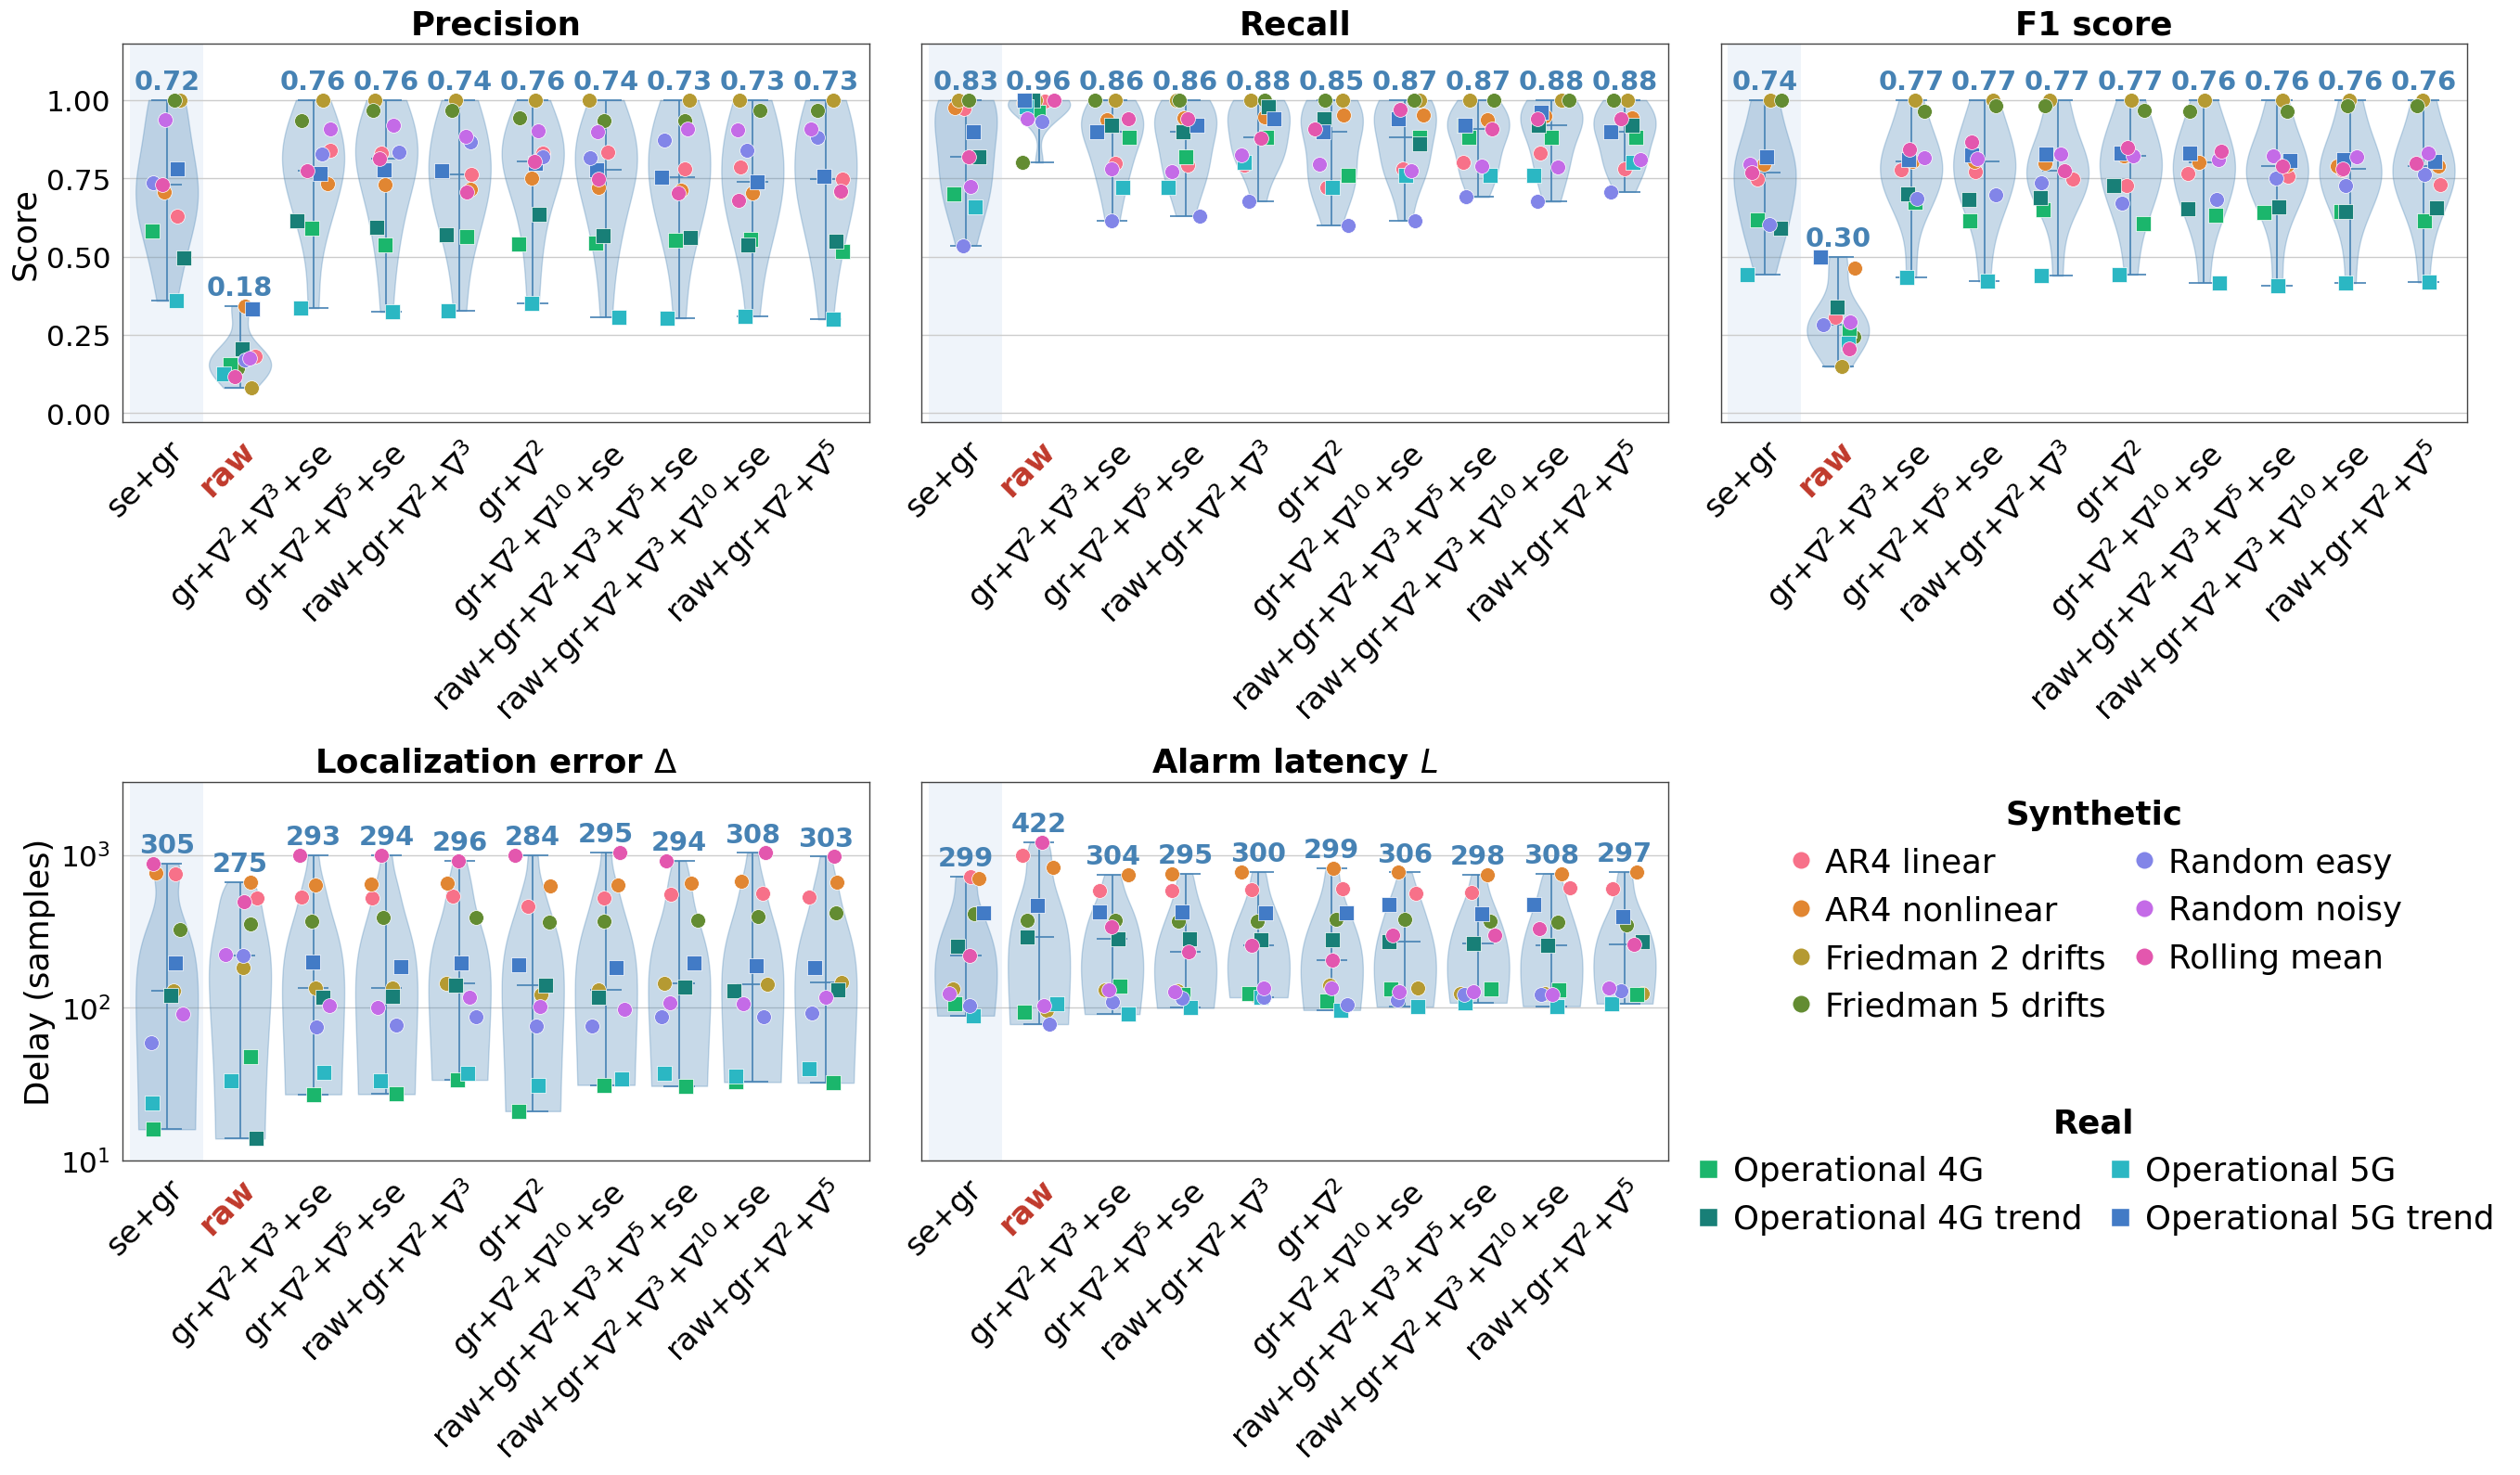

(<Figure size 2660x1400 with 6 Axes>,
 [[<Axes: title={'center': 'Precision'}, ylabel='Score'>,
   <Axes: title={'center': 'Recall'}>,
   <Axes: title={'center': 'F1 score'}>],
  [<Axes: title={'center': 'Localization error $\\Delta$'}, ylabel='Delay (samples)'>,
   <Axes: title={'center': 'Alarm latency $L$'}>]])

In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import seaborn as sns
import re
from matplotlib.lines import Line2D

number_of_benchmarks = 7
REAL_TS = ["infocom_4G_add_hour", "infocom_4G_add_hour_trend",
           "infocom_5G_add_hour", "infocom_5G_add_hour_trend"]

TS_COLORS = {
    "AR4_linear_1": "#f77189", "AR4_nonlinear_1": "#e18632", "friedman_2_drifts": "#b59a32",
    "friedman_5_drifts": "#638c32", "random_easy": "#8285e8", "random_noisy": "#c46be7",
    "rolling_mean": "#e357ae",
    "infocom_4G_add_hour": "#1bb66c", "infocom_4G_add_hour_trend": "#187f77",
    "infocom_5G_add_hour": "#2bb7c3", "infocom_5G_add_hour_trend": "#427bc6",
}

DERIV_STYLES = {                                   # how "2d", "3d", ... are rendered
    "math":    lambda n: rf"$\mathrm{{d}}^{{{n}}}$",
    "paren":   lambda n: rf"$\mathrm{{d}}^{{({n})}}$",
    "partial": lambda n: rf"$\partial^{{{n}}}$",
    "nabla":   lambda n: rf"$\nabla^{{{n}}}$",
    "delta":   lambda n: rf"$\Delta^{{{n}}}$",
}


def pretty_model(name, deriv_style="math", token_titles=None, sep="+"):
    """'raw+gr+2d+3d+se' -> 'raw+gr+d²+d³+se' in the chosen style."""
    token_titles = token_titles or {}
    fmt = DERIV_STYLES[deriv_style] if isinstance(deriv_style, str) else deriv_style
    out = []
    for tok in name.split("+"):
        m = re.fullmatch(r"(\d+)d", tok.strip())
        out.append(fmt(int(m.group(1))) if m else token_titles.get(tok, tok))
    return sep.join(out)


def select_models(ranking, top_n=10, must_include=("se+gr",), exclude=()):
    """Top-N models of a ranking (index = model, sorted best first), minus `exclude`,
    with `must_include` always present (prepended)."""
    top = [m for m in ranking.index if m not in exclude and m not in must_include][:top_n]
    return [m for m in must_include if m in ranking.index] + top


def plot_metrics_grid_v2(plot_df, plot_dist_df, ylim=None, exclude_ts=None,
                         model_order=None, highlight=None, label_colors=None,
                         deriv_style=None, token_titles=None,
                         real_ts=REAL_TS, real_marker="s", synthetic_marker="o",
                         group_labels=("Synthetic", "Real"),
                         save="figures/results.pdf", metric_titles=None, ts_titles=None, model_titles=None,
                         figsize=(26, 13), ncols=3,
                         fontsize=16, tick_fontsize=None, model_fontsize=None, legend_fontsize=None,
                         annot_fontsize=11, annot_rotation=0,
                         text_color="black", violin_color="steelblue", dot_size=60,
                         border_color="#444444", border_width=1.0,
                         wspace=0.07, hspace=0.62, xlabel_rotation=45,
                         left=0.045, right=0.995, top=0.96, bottom=0.1,
                         legend_markersize=10, legend_colspacing=0.7, legend_titles=True,
                         legend_cols=2, legend_gap=0.04,
                         ylabel_score="Score", ylabel_delay="Delay (samples)", log_headroom=15,
                         bw_method=None, ylim_delay=None, font_scale=1.0, bold_family="DejaVu Sans"):
    """
    Two-row grid: score metrics of plot_df on top (linear axis), delay metrics of plot_dist_df
    below (log axis), legends in the free bottom-right cell.
    model_order : explicit order of the models (default: order of appearance in plot_df).
    highlight   : models shaded blue; moved to the front, everything else shaded orange.
                  If None, the last `number_of_benchmarks` models are shaded orange.
    label_colors: {model: colour}; only that model's name on the x-axis is coloured (and bold).
    deriv_style : render the derivative tokens ("2d", "3d", ...) of the model names with pretty_model().
    """
    if exclude_ts:
        plot_df = plot_df[~plot_df["time_series"].isin(exclude_ts)].copy()
        plot_dist_df = plot_dist_df[~plot_dist_df["time_series"].isin(exclude_ts)].copy()

    sns.set_theme(style="whitegrid")                 # resets font.family -> set fonts AFTER this
    tick_fontsize = tick_fontsize or fontsize - 2
    model_fontsize = model_fontsize or fontsize - 1
    legend_fontsize = legend_fontsize or fontsize - 3
    fontsize, tick_fontsize, model_fontsize, legend_fontsize, annot_fontsize = (
        v * font_scale for v in (fontsize, tick_fontsize, model_fontsize, legend_fontsize, annot_fontsize))
    mpl.rcParams.update({
        "font.family": "sans-serif", "font.sans-serif": ["DejaVu Sans"],
        "mathtext.fontset": "dejavusans", "axes.formatter.use_mathtext": False,
        "pdf.fonttype": 42, "ps.fonttype": 42,
        "font.size": fontsize, "axes.labelsize": fontsize, "axes.titlesize": fontsize,
        "xtick.labelsize": model_fontsize, "ytick.labelsize": tick_fontsize,
        "legend.fontsize": legend_fontsize,
        "text.color": text_color, "axes.labelcolor": text_color, "axes.titlecolor": text_color,
        "xtick.color": text_color, "ytick.color": text_color,
    })
    metric_titles = metric_titles or {}
    ts_titles = ts_titles or {}
    model_titles = model_titles or {}
    label_colors = label_colors or {}
    real_ts = set(real_ts)
    if deriv_style is not None:                     # explicit model_titles still win
        model_titles = {**{m: pretty_model(m, deriv_style, token_titles)
                           for m in plot_df["model"].dropna().unique()}, **model_titles}

    # ---- model order: explicit > order of appearance; highlighted models first
    present = list(plot_df["model"].dropna().unique())
    model_order = [m for m in (model_order or present) if m in present]
    if highlight is not None:
        highlight = [m for m in highlight if m in model_order]
        model_order = highlight + [m for m in model_order if m not in highlight]
        half = len(highlight)
    else:
        half = len(model_order) - number_of_benchmarks
    n_models = len(model_order)

    lin_metrics = list(plot_df["metric"].dropna().unique())
    log_metrics = list(plot_dist_df["metric"].dropna().unique())

    all_ts = list(pd.unique(pd.concat([plot_df["time_series"], plot_dist_df["time_series"]]).dropna()))
    ts_palette = sns.color_palette("husl", n_colors=len(all_ts))
    ts_colors = {**{ts: ts_palette[i] for i, ts in enumerate(all_ts)}, **TS_COLORS}
    ts_marker = {ts: (real_marker if ts in real_ts else synthetic_marker) for ts in all_ts}
    syn = [ts for ts in all_ts if ts not in real_ts]
    rea = [ts for ts in all_ts if ts in real_ts]
    rng = np.random.default_rng(42)

    log_vals = pd.concat([plot_dist_df[plot_dist_df["metric"] == m]["mean"] for m in log_metrics]) \
        if log_metrics else pd.Series(dtype=float)
    log_vals = log_vals[log_vals > 0]
    log_lo, log_hi = (log_vals.min(), log_vals.max()) if len(log_vals) else (1, 10)

    # ---- grid: rows = [scores, delays]; the delay row leaves its last cell(s) for the legends
    rows = [(lin_metrics, plot_df, False, ylabel_score), (log_metrics, plot_dist_df, True, ylabel_delay)]
    rows = [r for r in rows if r[0]]
    ncols = max(ncols, *(len(r[0]) for r in rows))
    fig = plt.figure(figsize=figsize)
    gs = fig.add_gridspec(len(rows), ncols, wspace=wspace, hspace=hspace,
                          left=left, right=right, top=top, bottom=bottom)

    axes = []
    legend_cell = None
    for r, (metrics, df, symlog, ylabel) in enumerate(rows):
        row_axes = []
        for c, metric in enumerate(metrics):
            ax = fig.add_subplot(gs[r, c], sharey=row_axes[0] if row_axes else None)
            row_axes.append(ax)

            if half > 0:
                ax.axvspan(-0.5, half - 0.5, color="#dce8f5", alpha=0.45, zorder=0, lw=0)
            if half < n_models:
                ax.axvspan(half - 0.5, n_models - 0.5, color="#ffffff", alpha=0.45, zorder=0, lw=0)

            for j, model in enumerate(model_order):
                means = df[(df["model"] == model) & (df["metric"] == metric)].set_index("time_series")["mean"].dropna()
                if symlog:
                    means = means[means != 0]
                if means.empty:
                    continue
                vals = means.values
                if len(vals) >= 2:
                    parts = ax.violinplot([vals], positions=[j], widths=0.85, showmedians=True,
                                          showextrema=True, bw_method=bw_method)
                    for pc in parts["bodies"]:
                        pc.set_facecolor(violin_color); pc.set_alpha(0.3); pc.set_edgecolor(violin_color)
                    for key in ("cmedians", "cmins", "cmaxes", "cbars"):
                        if key in parts:
                            parts[key].set_color(violin_color); parts[key].set_linewidth(1.2)
                jitter = rng.uniform(-0.25, 0.25, size=len(means))
                for (ts, val), jit in zip(means.items(), jitter):
                    ax.scatter(j + jit, val, color=ts_colors.get(ts, "gray"), marker=ts_marker.get(ts, "o"),
                               s=dot_size, zorder=4, edgecolors="white", linewidths=0.5)
                ax.annotate(f"{vals.mean():{'.0f' if symlog else '.2f'}}", xy=(j, vals.max()),
                            xytext=(0, 4), textcoords="offset points", ha="center", va="bottom",
                            fontsize=annot_fontsize, color=violin_color, fontfamily=bold_family, fontweight="bold",
                            rotation=annot_rotation)

            ax.set_title(metric_titles.get(metric, metric), pad=8, fontfamily=bold_family, fontweight="bold")
            ax.set_xticks(range(n_models))
            ax.set_xticklabels([model_titles.get(m, m) for m in model_order],
                               rotation=xlabel_rotation,
                               ha="right" if 0 < xlabel_rotation < 90 else "center",
                               rotation_mode="anchor" if 0 < xlabel_rotation < 90 else "default")
            for lab, m in zip(ax.get_xticklabels(), model_order):     # coloured model names
                if m in label_colors:
                    lab.set_color(label_colors[m]); lab.set_fontfamily(bold_family); lab.set_fontweight("bold")
            ax.set_xlim(-0.6, n_models - 0.4)
            ax.grid(axis="x", visible=False)

            if symlog:
                ax.set_yscale("log")
                ax.set_ylim(*(ylim_delay if ylim_delay is not None else (log_lo / 2, log_hi * log_headroom)))
            else:
                ax.set_ylim(*(ylim if ylim is not None else (-0.03, 1.18)))
            if c == 0:
                ax.set_ylabel(ylabel)
            else:
                ax.tick_params(labelleft=False)
            for sp in ax.spines.values():
                sp.set_visible(True); sp.set_color(border_color); sp.set_linewidth(border_width)
        axes.append(row_axes)
        if len(metrics) < ncols and legend_cell is None:
            legend_cell = gs[r, len(metrics):]              # free cell(s) on this row -> legends

    # ---- legends: two stacked boxes in the free cell (or above the grid if every cell is used)
    def _handles(ts_list):
        return [Line2D([], [], ls="", marker=ts_marker[ts], color=ts_colors[ts], mec="white",
                       ms=legend_markersize, label=ts_titles.get(ts, ts)) for ts in ts_list]

    def _kw(title):
        kw = dict(labelcolor=text_color, frameon=False, edgecolor=border_color, fancybox=False,
                  handlelength=0.9, handletextpad=0.3, columnspacing=legend_colspacing,
                  borderpad=0.5, borderaxespad=0.0, ncols=legend_cols)
        if legend_titles:
            kw.update(title=title, alignment="center",
                      title_fontproperties={"family": bold_family, "size": legend_fontsize, "weight": "bold"})
        return kw

    if legend_cell is not None:
        lax = fig.add_subplot(legend_cell); lax.axis("off")
        x0, y0, x1, y1 = lax.get_position().extents
        xc = (x0 + x1) / 2
        leg1 = fig.legend(handles=_handles(syn), loc="upper center", bbox_to_anchor=(xc, y1),
                          **_kw(group_labels[0]))
        fig.canvas.draw()                                    # need its height to stack the second box
        h1 = leg1.get_window_extent().transformed(fig.transFigure.inverted()).height
        leg2 = fig.legend(handles=_handles(rea), loc="upper center",
                          bbox_to_anchor=(xc, y1 - h1 - legend_gap), **_kw(group_labels[1]))
    else:
        leg1 = fig.legend(handles=_handles(syn), loc="lower left", bbox_to_anchor=(left, 0.97), **_kw(group_labels[0]))
        leg2 = fig.legend(handles=_handles(rea), loc="lower right", bbox_to_anchor=(right, 0.97), **_kw(group_labels[1]))

    if save:
        plt.savefig(save, bbox_inches="tight")
    plt.show()
    return fig, axes


selected = select_models(ranking, top_n=8, must_include=[OURS, "raw"], exclude=benchmark_ts)
print(f"{len(selected)} models:", selected)

plot_metrics_grid_v2(
    plot_df[plot_df["model"].isin(selected)],
    plot_dist_df[plot_dist_df["model"].isin(selected)],
    ylim=None, exclude_ts=EXCLUDE_TS,
    model_order=selected,                        # keep the ranking order (ours, raw, combinations)
    highlight=[OURS],                            # only ours on the blue band; raw + combinations orange
    label_colors={"raw": "#c0392b"},             # only the name "raw" in red
    deriv_style="nabla",                         # 2d, 3d, ... -> ∇², ∇³   (also "math", "paren", "partial", "delta")
    save="figures/results_combinations_v3.pdf",
    fontsize=16, annot_fontsize=13, annot_rotation=0,
    figsize=(26 + 0.6 * max(len(selected) - 9, 0), 14),
    font_scale=1.6, legend_fontsize=16,
    xlabel_rotation=45, hspace=0.95,             # a bit more row gap: the combination names are longer
    dot_size=130, legend_markersize=14,
    ylim_delay=(10, 3000),
    metric_titles={
        "F1 Score":                               "F1 score",
        "Miss Detection Rate":                    "Miss detection rate",
        "Sum Both Early and Late Detections":     r"Localization error $\Delta$",
        "Sum Both Early and Late Detections end": r"Alarm latency $L$",
    },
    ts_titles={
        "AR4_linear_1":              "AR4 linear",
        "AR4_nonlinear_1":           "AR4 nonlinear",
        "friedman_2_drifts":         "Friedman 2 drifts",
        "friedman_5_drifts":         "Friedman 5 drifts",
        "infocom_4G_add_hour":       "Operational 4G",
        "infocom_4G_add_hour_trend": "Operational 4G trend",
        "infocom_5G_add_hour":       "Operational 5G",
        "infocom_5G_add_hour_trend": "Operational 5G trend",
        "random_easy":               "Random easy",
        "random_noisy":              "Random noisy",
        "rolling_mean":              "Rolling mean",
    },
)

In [13]:
r = ranking[~ranking["is_benchmark"]].copy()
r["n_views"] = r.index.str.count(r"\+") + 1          # "gr+2d+se" -> 3 views
odd = r[r["n_views"] % 2 == 1]

# range per number of views
f1 = odd.groupby("n_views")["F1 Score"]
summary = f1.agg(n="count", min="min", median="median", max="max")
summary["worst"] = f1.idxmin()
summary["best"] = f1.idxmax()
display(summary.round(3))

# one overall range for the text
print(f"odd number of views: F1 {odd['F1 Score'].min():.3f}–{odd['F1 Score'].max():.3f} "
      f"over {len(odd)} combinations")

# same for precision and recall, if needed
display(odd.groupby("n_views")[quality_metrics].agg(["min", "max"]).round(3))

,n,min,median,max,worst,best
n_views,,,,,,
1,10,0.207,0.551,0.657,fft,2d
3,11,0.301,0.645,0.692,raw+gr+tr,raw+2d+3d


odd number of views: F1 0.207–0.692 over 21 combinations


metric  Precision        Recall        F1 Score       
              min    max    min    max      min    max
n_views                                               
1           0.123  0.577  0.824  0.986    0.207  0.657
3           0.187  0.612  0.880  0.963    0.301  0.692